In [1]:
%pip -q install lightgbm==4.6.0 PyYAML==6.0.2 shap==0.48.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 759.5/759.5 kB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 35.3 MB/s eta 0:00:00


In [2]:
from pathlib import Path
import zipfile
import json
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import lightgbm as lgb
import shap
import yaml
import joblib

from IPython.display import display
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

OUTPUT = Path("/content/stage4_results")
OUTPUT.mkdir(exist_ok=True)

print("Библиотеки подключены")

Библиотеки подключены


In [3]:
csv_path = Path("/content/NBK_BNS_variant6_2016_2025.csv")
zip_path = Path("/content/stage3_results.zip")

assert csv_path.exists(), "Загрузите CSV."
assert zip_path.exists(), "Загрузите stage3_results.zip."

stage3_dir = Path("/content/stage3_loaded")
stage3_dir.mkdir(exist_ok=True)

required_files = [
    "config.yaml",
    "stage3_models.joblib",
    "validation_comparison.csv",
    "requirements_stage3.txt",
]

with zipfile.ZipFile(zip_path) as archive:
    for name in required_files:
        assert name in archive.namelist(), f"В архиве нет {name}"
        (stage3_dir / name).write_bytes(archive.read(name))

print("Файлы третьего этапа извлечены")

Файлы третьего этапа извлечены


In [4]:
saved = joblib.load(stage3_dir / "stage3_models.joblib")

config = saved["config"]
baseline_models = saved["baseline_models"]
boosting_models = saved["boosting_models"]

assert config["test_used"] is False
assert config["refit_before_test"] is False

FEATURE_LAG = int(config["feature_lag_months"])

TRAIN_END = pd.Timestamp(config["train_end"])
VALID_END = pd.Timestamp(config["validation_end"])

targets = {
    "business": "Y_business_change_pp",
    "households": "Y_households_change_pp",
}

group_names = {
    "business": "Юридические лица",
    "households": "Физические лица, включая ИП",
}

for group in targets:
    print(
        group_names[group],
        "— модель, выбранная на validation:",
        config["selected_models"][group]
    )

Юридические лица — модель, выбранная на validation: zero_change
Физические лица, включая ИП — модель, выбранная на validation: lightgbm


In [5]:
data = pd.read_csv(csv_path, encoding="utf-8-sig")

data["month"] = pd.to_datetime(
    data["month"], format="%Y-%m", errors="raise"
)

data = data.sort_values("month").reset_index(drop=True)

numeric_columns = data.columns.drop("month")
data[numeric_columns] = data[numeric_columns].apply(
    pd.to_numeric, errors="raise"
)

assert np.isfinite(data[numeric_columns].to_numpy()).all()

assert pd.DatetimeIndex(data["month"]).equals(
    pd.date_range("2016-01-01", "2025-12-01", freq="MS")
)

print("Данные проверены")

Данные проверены


In [6]:
def make_macro_features(frame, lag=2):
    frame = frame.sort_values("month").reset_index(drop=True)
    features = pd.DataFrame(index=frame.index)

    inflation = frame["inflation_yoy_pct"]
    base = frame["base_rate_pct"]
    change = inflation.diff().round(10)

    features["inflation_yoy_lag2"] = inflation.shift(lag)
    features["inflation_mom_lag2"] = (
        frame["inflation_mom_pct"].shift(lag)
    )

    features["inflation_change_lag2"] = change.shift(lag)
    features["inflation_up_lag2"] = change.clip(lower=0).shift(lag)
    features["inflation_down_lag2"] = change.clip(upper=0).shift(lag)

    features["base_rate_lag2"] = base.shift(lag)
    features["base_change_lag2"] = base.diff().shift(lag)

    features["inflation_mean3_lag2"] = (
        inflation.rolling(3).mean().shift(lag)
    )
    features["inflation_std3_lag2"] = (
        inflation.rolling(3).std().shift(lag)
    )

    features["real_base_proxy_lag2"] = (base - inflation).shift(lag)

    return features

In [7]:
def make_features(frame, group, lag=2):
    frame = frame.sort_values("month").reset_index(drop=True)
    features = make_macro_features(frame, lag)

    rate = frame[f"loan_{group}_pct"]
    change = frame[targets[group]]

    features["loan_rate_lag2"] = rate.shift(lag)
    features["loan_change_lag2"] = change.shift(lag)
    features["loan_change_lag3"] = change.shift(lag + 1)

    features["loan_change_mean3_lag2"] = (
        change.rolling(3).mean().shift(lag)
    )
    features["loan_change_std3_lag2"] = (
        change.rolling(3).std().shift(lag)
    )

    features["loan_base_spread_lag2"] = (
        rate - frame["base_rate_pct"]
    ).shift(lag)

    return features

In [8]:
evaluation_data = {}

for group, target in targets.items():
    X = make_features(data, group, FEATURE_LAG)

    assert X.columns.tolist() == config["feature_columns"]

    usable = X.notna().all(axis=1)
    train_mask = usable & (data["month"] <= TRAIN_END)
    test_mask = usable & (data["month"] > VALID_END)

    assert train_mask.sum() == 79
    assert test_mask.sum() == 18

    evaluation_data[group] = {
        "X_train": X.loc[train_mask].copy(),
        "X_test": X.loc[test_mask].copy(),
        "y_test": data.loc[test_mask, target].copy(),
        "dates_test": data.loc[test_mask, "month"].copy(),
    }

    print(group_names[group], "— test: 18 месяцев")

Юридические лица — test: 18 месяцев
Физические лица, включая ИП — test: 18 месяцев


In [9]:
def predict_model(group, name, X):
    if name == "zero_change":
        return np.zeros(len(X))

    if name == "lightgbm":
        model = boosting_models[group]
        return np.asarray(
            model.predict(X, num_iteration=model.best_iteration_)
        )

    columns = config["baseline_columns"][name]

    X_regression = sm.add_constant(
        X[columns], has_constant="add"
    )

    return np.asarray(
        baseline_models[group][name].predict(X_regression)
    )

print("Функция прогнозирования готова")

Функция прогнозирования готова


In [10]:
test_predictions = {}
test_rows = []

for group, parts in evaluation_data.items():
    test_predictions[group] = {}

    for name in [
        "zero_change", "symmetric", "asymmetric", "lightgbm"
    ]:
        prediction = predict_model(group, name, parts["X_test"])
        test_predictions[group][name] = prediction

        test_rows.append({
            "group": group,
            "model": name,
            "selected_on_validation":
                name == config["selected_models"][group],
            "RMSE": float(np.sqrt(mean_squared_error(
                parts["y_test"], prediction
            ))),
            "MAE": float(mean_absolute_error(
                parts["y_test"], prediction
            )),
            "R2": float(r2_score(
                parts["y_test"], prediction
            )),
        })

test_metrics = pd.DataFrame(test_rows)

display(test_metrics.round(4))

test_metrics.to_csv(
    OUTPUT / "test_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

,group,model,selected_on_validation,RMSE,MAE,R2
0,business,zero_change,True,0.3163,0.2533,-0.1196
1,business,symmetric,False,0.3029,0.2448,-0.0265
2,business,asymmetric,False,0.2979,0.2424,0.0075
3,business,lightgbm,False,0.3106,0.2501,-0.0789
4,households,zero_change,False,1.2561,0.9570,-0.0040
5,households,symmetric,False,1.3186,1.1544,-0.1066
6,households,asymmetric,False,1.3139,1.1472,-0.0986
7,households,lightgbm,True,1.2342,1.0849,0.0306


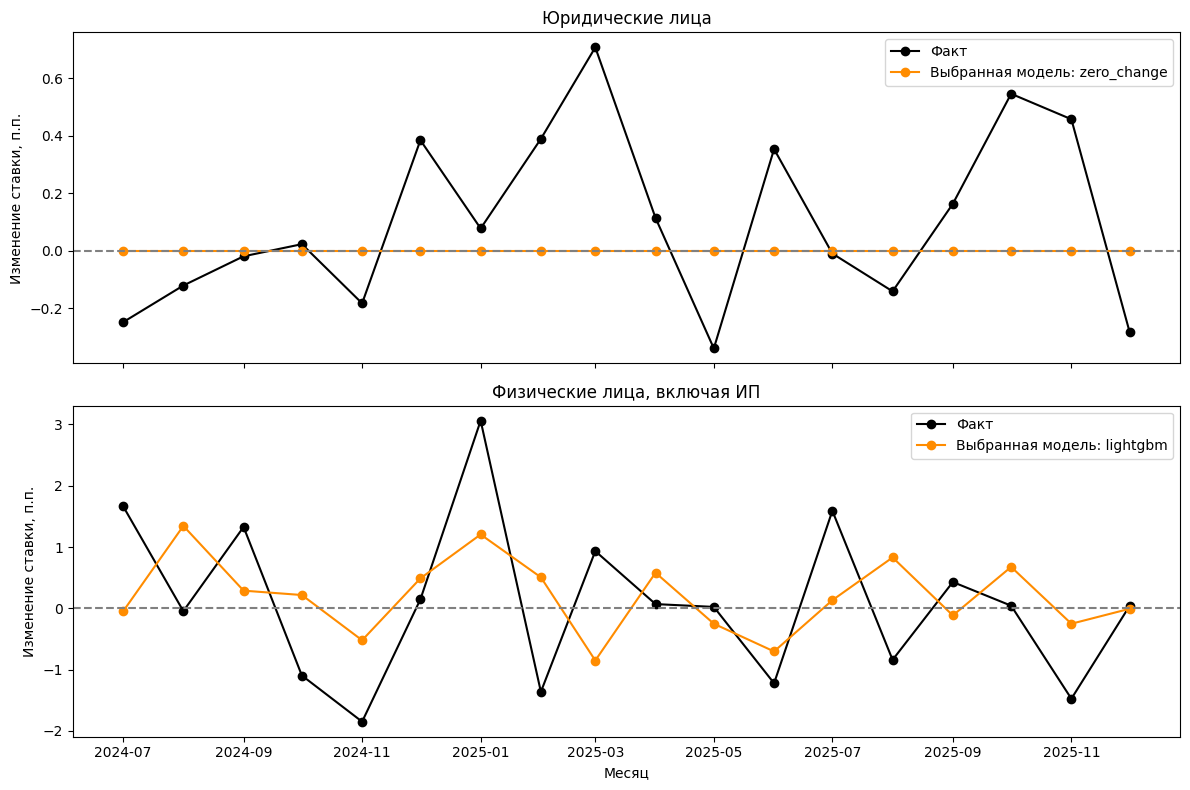

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

for ax, group in zip(axes, targets):
    parts = evaluation_data[group]
    selected = config["selected_models"][group]

    ax.plot(
        parts["dates_test"], parts["y_test"],
        color="black", marker="o", label="Факт"
    )

    ax.plot(
        parts["dates_test"],
        test_predictions[group][selected],
        color="darkorange", marker="o",
        label=f"Выбранная модель: {selected}"
    )

    ax.axhline(0, color="gray", linestyle="--")
    ax.set_title(group_names[group])
    ax.set_ylabel("Изменение ставки, п.п.")
    ax.legend()

axes[1].set_xlabel("Месяц")
plt.tight_layout()

plt.savefig(OUTPUT / "selected_models_test.png", dpi=160)
plt.show()

In [12]:
prediction_tables = []

for group, parts in evaluation_data.items():
    table = pd.DataFrame({
        "month": parts["dates_test"].to_numpy(),
        "group": group,
        "actual_change_pp": parts["y_test"].to_numpy(),
    })

    for name, prediction in test_predictions[group].items():
        table[f"prediction_{name}"] = prediction

    prediction_tables.append(table)

test_prediction_table = pd.concat(
    prediction_tables, ignore_index=True
)

test_prediction_table.to_csv(
    OUTPUT / "test_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

display(test_prediction_table.head())

,month,group,actual_change_pp,prediction_zero_change,prediction_symmetric,prediction_asymmetric,prediction_lightgbm
0,2024-07-01,business,-0.248898,0.0,0.016574,-0.016996,0.018037
1,2024-08-01,business,-0.121411,0.0,-0.017477,-0.037473,0.023757
2,2024-09-01,business,-0.019791,0.0,0.009362,0.007238,0.010427
3,2024-10-01,business,0.022357,0.0,-0.020963,-0.039869,0.023757
4,2024-11-01,business,-0.183365,0.0,0.003825,-0.025024,0.023757


In [13]:
wald_rows = []

for group in targets:
    model = baseline_models[group]["asymmetric"]

    result = model.wald_test(
        "inflation_up_lag2 = inflation_down_lag2",
        use_f=False,
        scalar=True
    )

    p_value = float(result.pvalue)

    wald_rows.append({
        "group": group,
        "beta_up": float(model.params["inflation_up_lag2"]),
        "beta_down": float(model.params["inflation_down_lag2"]),
        "wald_p_value": p_value,
        "reject_symmetry_at_5pct": p_value < 0.05,
    })

wald_results = pd.DataFrame(wald_rows)
display(wald_results.round(4))

wald_results.to_csv(
    OUTPUT / "wald_train.csv",
    index=False,
    encoding="utf-8-sig"
)

,group,beta_up,beta_down,wald_p_value,reject_symmetry_at_5pct
0,business,0.2089,0.0650,0.5807,False
1,households,-0.1365,0.0768,0.2163,False


In [14]:
boost_explanations = {}
boost_train_explanations = {}

for group, parts in evaluation_data.items():
    explainer = shap.TreeExplainer(
        boosting_models[group],
        feature_perturbation="tree_path_dependent"
    )

    boost_explanations[group] = explainer(parts["X_test"])
    boost_train_explanations[group] = explainer(parts["X_train"])

    explanation = boost_explanations[group]

    reconstructed = (
        explanation.base_values +
        explanation.values.sum(axis=1)
    )

    assert np.allclose(
        reconstructed,
        test_predictions[group]["lightgbm"],
        atol=1e-6
    )

print("SHAP рассчитан, совпадение с прогнозами проверено")

SHAP рассчитан, совпадение с прогнозами проверено


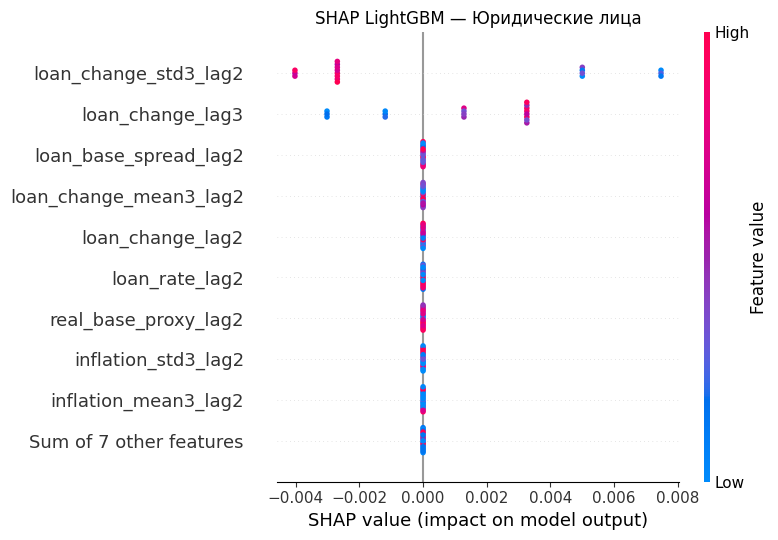

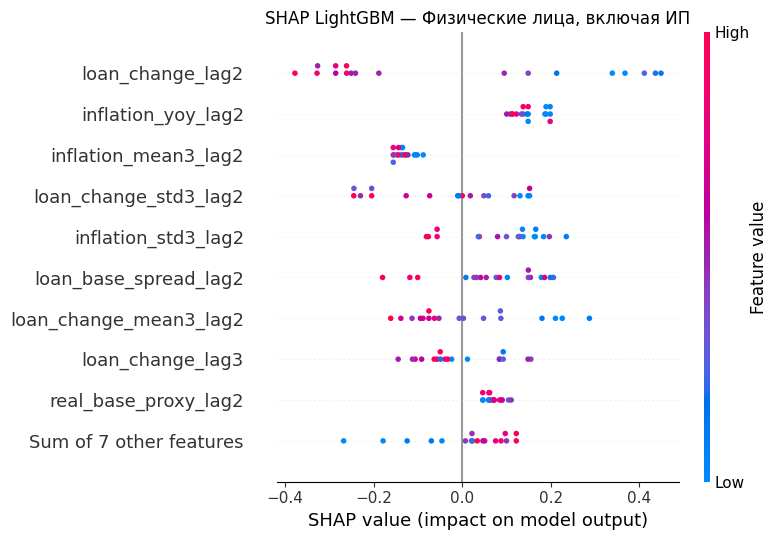

In [15]:
for group in targets:
    shap.plots.beeswarm(
        boost_explanations[group],
        max_display=10,
        show=False
    )

    plt.title(f"SHAP LightGBM — {group_names[group]}")
    plt.tight_layout()

    plt.savefig(
        OUTPUT / f"shap_lightgbm_{group}.png",
        dpi=160,
        bbox_inches="tight"
    )

    plt.show()

In [16]:
selected_explanations = {}

for group, parts in evaluation_data.items():
    name = config["selected_models"][group]
    X_test = parts["X_test"]
    X_train = parts["X_train"]

    if name == "lightgbm":
        explanation = boost_explanations[group]

    else:
        coefficients = pd.Series(0.0, index=X_test.columns)
        intercept = 0.0

        if name != "zero_change":
            model = baseline_models[group][name]
            columns = config["baseline_columns"][name]

            coefficients.loc[columns] = model.params[columns]
            intercept = float(model.params["const"])

        train_mean = X_train.mean()

        contributions = (
            (X_test - train_mean) * coefficients
        ).to_numpy()

        base_value = float(
            intercept + (train_mean * coefficients).sum()
        )

        explanation = shap.Explanation(
            values=contributions,
            base_values=np.full(len(X_test), base_value),
            data=X_test.to_numpy(),
            feature_names=X_test.columns.tolist()
        )

    assert np.allclose(
        explanation.base_values + explanation.values.sum(axis=1),
        test_predictions[group][name],
        atol=1e-6
    )

    selected_explanations[group] = explanation

print("Объяснения выбранных моделей готовы")

Объяснения выбранных моделей готовы


Юридические лица 2024-07 | Модель: zero_change | Факт: -0.249 | Прогноз: 0.0
Прогноз всегда 0; все вклады признаков равны нулю.
Юридические лица 2025-04 | Модель: zero_change | Факт: 0.114 | Прогноз: 0.0
Прогноз всегда 0; все вклады признаков равны нулю.
Юридические лица 2025-12 | Модель: zero_change | Факт: -0.284 | Прогноз: 0.0
Прогноз всегда 0; все вклады признаков равны нулю.
Физические лица, включая ИП 2024-07 | Модель: lightgbm | Факт: 1.666 | Прогноз: -0.05


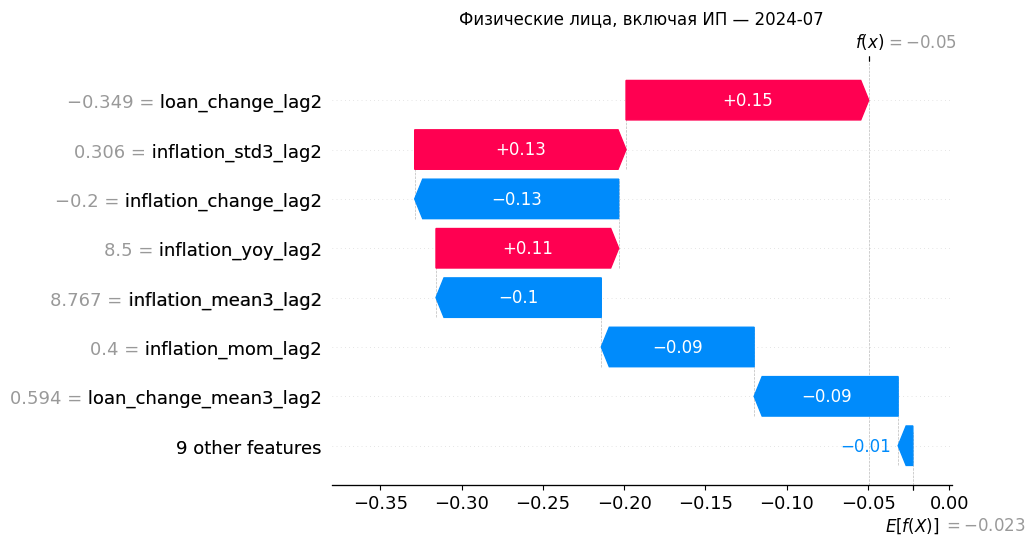

Физические лица, включая ИП 2025-04 | Модель: lightgbm | Факт: 0.069 | Прогноз: 0.58


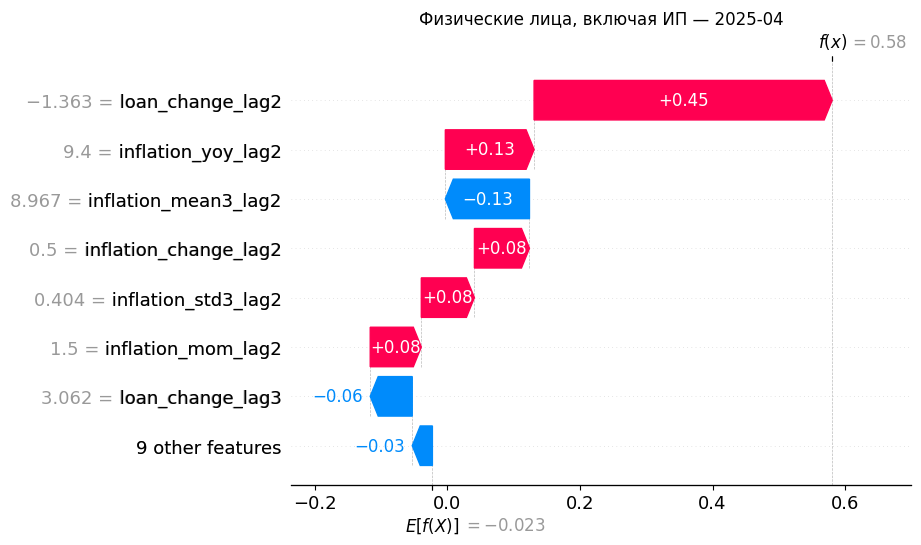

Физические лица, включая ИП 2025-12 | Модель: lightgbm | Факт: 0.041 | Прогноз: -0.008


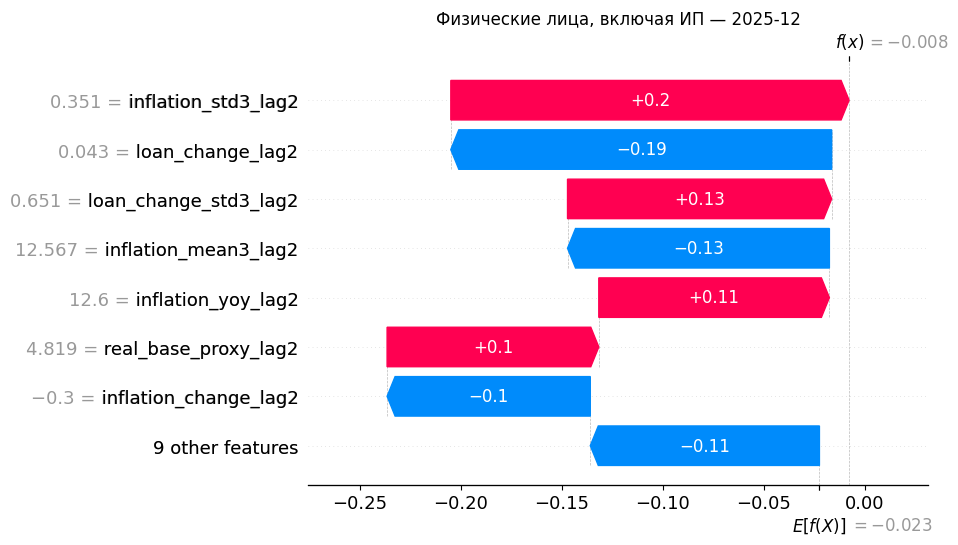

,group,month,model,feature,feature_value,shap_contribution_pp
0,business,2024-07,zero_change,inflation_yoy_lag2,8.5000,-0.0000
1,business,2024-07,zero_change,inflation_mom_lag2,0.4000,-0.0000
2,business,2024-07,zero_change,inflation_change_lag2,-0.2000,-0.0000
3,business,2025-04,zero_change,inflation_yoy_lag2,9.4000,0.0000
4,business,2025-04,zero_change,inflation_mom_lag2,1.5000,0.0000
5,business,2025-04,zero_change,inflation_change_lag2,0.5000,0.0000
6,business,2025-12,zero_change,inflation_yoy_lag2,12.6000,0.0000
7,business,2025-12,zero_change,inflation_mom_lag2,0.5000,-0.0000
8,business,2025-12,zero_change,inflation_change_lag2,-0.3000,-0.0000
9,households,2024-07,lightgbm,loan_change_lag2,-0.3488,0.1492


In [17]:
case_rows = []

for group, parts in evaluation_data.items():
    name = config["selected_models"][group]
    explanation = selected_explanations[group]
    positions = [0, len(parts["X_test"]) // 2, len(parts["X_test"]) - 1]

    for position in positions:
        month = parts["dates_test"].iloc[position].strftime("%Y-%m")

        print(
            group_names[group], month,
            "| Модель:", name,
            "| Факт:", round(float(parts["y_test"].iloc[position]), 3),
            "| Прогноз:", round(
                float(test_predictions[group][name][position]), 3
            )
        )

        if name == "zero_change":
            print("Прогноз всегда 0; все вклады признаков равны нулю.")
        else:
            shap.plots.waterfall(
                explanation[position],
                max_display=8,
                show=False
            )

            plt.title(f"{group_names[group]} — {month}")
            plt.savefig(
                OUTPUT / f"shap_case_{group}_{month}.png",
                dpi=160,
                bbox_inches="tight"
            )
            plt.show()

        contributions = pd.Series(
            explanation.values[position],
            index=parts["X_test"].columns
        )

        top = contributions.abs().nlargest(3).index

        for feature in top:
            case_rows.append({
                "group": group,
                "month": month,
                "model": name,
                "feature": feature,
                "feature_value": float(
                    parts["X_test"].iloc[position][feature]
                ),
                "shap_contribution_pp": float(contributions[feature]),
            })

case_details = pd.DataFrame(case_rows)
display(case_details.round(4))

case_details.to_csv(
    OUTPUT / "three_cases_per_group.csv",
    index=False,
    encoding="utf-8-sig"
)

In [18]:
def calculate_psi(expected, actual, bins=5):
    expected = np.asarray(expected, dtype=float)
    actual = np.asarray(actual, dtype=float)

    assert np.isfinite(expected).all()
    assert np.isfinite(actual).all()

    if np.unique(expected).size == 1:
        value = expected[0]

        cuts = np.array([
            -np.inf,
            value,
            np.nextafter(value, np.inf),
            np.inf
        ])
    else:
        quantiles = np.unique(
            np.quantile(expected, np.linspace(0, 1, bins + 1))
        )
        cuts = np.r_[-np.inf, quantiles, np.inf]

    expected_counts = np.histogram(expected, bins=cuts)[0]
    actual_counts = np.histogram(actual, bins=cuts)[0]

    smoothing = 0.5
    number_bins = len(expected_counts)

    e = (
        (expected_counts + smoothing) /
        (len(expected) + smoothing * number_bins)
    )
    a = (
        (actual_counts + smoothing) /
        (len(actual) + smoothing * number_bins)
    )

    return float(np.sum((a - e) * np.log(a / e)))

print("Функция PSI готова")

Функция PSI готова


In [19]:
psi_rows = []

for group, parts in evaluation_data.items():
    selected = config["selected_models"][group]

    for name in sorted({selected, "lightgbm"}):
        train_prediction = predict_model(
            group, name, parts["X_train"]
        )
        test_prediction = test_predictions[group][name]

        psi_rows.append({
            "group": group,
            "item": f"prediction_{name}",
            "PSI": calculate_psi(train_prediction, test_prediction),
        })

    importance = pd.Series(
        np.abs(boost_train_explanations[group].values).mean(axis=0),
        index=parts["X_train"].columns
    )

    top_features = importance.sort_values(
        ascending=False, kind="stable"
    ).head(5).index

    if (importance > 0).sum() < 5:
        print(group, "— менее пяти признаков с ненулевым SHAP.")

    for feature in top_features:
        psi_rows.append({
            "group": group,
            "item": feature,
            "PSI": calculate_psi(
                parts["X_train"][feature],
                parts["X_test"][feature]
            ),
        })

psi_results = pd.DataFrame(psi_rows)
psi_results["flag_above_025"] = psi_results["PSI"] > 0.25

display(psi_results.round(4))

psi_results.to_csv(
    OUTPUT / "psi_results.csv",
    index=False,
    encoding="utf-8-sig"
)

business — менее пяти признаков с ненулевым SHAP.


,group,item,PSI,flag_above_025
0,business,prediction_lightgbm,0.1687,False
1,business,prediction_zero_change,0.0574,False
2,business,loan_change_std3_lag2,0.6790,True
3,business,loan_change_lag3,0.3877,True
4,business,inflation_yoy_lag2,1.3859,True
5,business,inflation_mom_lag2,0.5788,True
6,business,inflation_change_lag2,0.2520,True
7,households,prediction_lightgbm,0.1911,False
8,households,loan_change_lag2,0.3423,True
9,households,inflation_yoy_lag2,1.3859,True


In [20]:
ASSUMED_LOAN_AMOUNT_KZT = 1_000_000_000
ASSUMED_HORIZON_YEARS = 1

money_results = test_metrics[
    ["group", "model", "selected_on_validation", "MAE"]
].copy()

money_results["annual_income_error_equivalent_KZT"] = (
    money_results["MAE"] / 100
    * ASSUMED_LOAN_AMOUNT_KZT
    * ASSUMED_HORIZON_YEARS
)

display(money_results.round(2))

money_results.to_csv(
    OUTPUT / "scenario_money_equivalent.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Сценарий: 1 млрд ₸, постоянный остаток, срок 1 год.")
print("Не учтены фондирование, дефолты, расходы и изменение спроса.")
print("Это масштаб ошибки, а не фактическая прибыль.")

,group,model,selected_on_validation,MAE,annual_income_error_equivalent_KZT
0,business,zero_change,True,0.25,2532946.11
1,business,symmetric,False,0.24,2447870.20
2,business,asymmetric,False,0.24,2423986.52
3,business,lightgbm,False,0.25,2500699.49
4,households,zero_change,False,0.96,9570430.00
5,households,symmetric,False,1.15,11543814.06
6,households,asymmetric,False,1.15,11471990.50
7,households,lightgbm,True,1.08,10848844.53


Сценарий: 1 млрд ₸, постоянный остаток, срок 1 год.
Не учтены фондирование, дефолты, расходы и изменение спроса.
Это масштаб ошибки, а не фактическая прибыль.


In [21]:
final_bundle = {
    "baseline_models": baseline_models,
    "boosting_models": boosting_models,
    "config": config,
}

joblib.dump(final_bundle, OUTPUT / "model.pkl")

evaluation_config = dict(config)
evaluation_config["test_used"] = True
evaluation_config["money_scenario"] = {
    "loan_amount_KZT": ASSUMED_LOAN_AMOUNT_KZT,
    "horizon_years": ASSUMED_HORIZON_YEARS,
    "meaning": "Annual interest-income error equivalent, not realized profit"
}

with open(OUTPUT / "config.yaml", "w", encoding="utf-8") as file:
    yaml.safe_dump(
        evaluation_config,
        file,
        allow_unicode=True,
        sort_keys=False
    )

limitations = """
Ограничения исследования:
1. Совместная модель использует 2016–2025 вместо полного периода 2010–2025.
2. Физические лица включают ИП и не равны строго группе «население».
3. Доступность данных t−2 принята как допущение; календарь публикаций
   не проверен. Нужно учитывать и доступность целевых значений train
   на дату первого валидационного прогноза.
4. Используется актуальная историческая выгрузка, а не архив первых
   публикаций: возможны пересмотры.
5. Период 2024–2025 уже рассматривался в прежней учебной работе.
6. Test содержит только 18 месяцев; оценки качества и PSI неустойчивы.
7. SHAP объясняет модель, а не доказывает причинность.
8. Денежная оценка — условный эквивалент ошибки, не фактическая прибыль.
9. После просмотра test параметры и выбор модели не менялись
   в данном блокноте.
"""

(OUTPUT / "limitations.txt").write_text(
    limitations.strip(), encoding="utf-8"
)

print("model.pkl, config.yaml и ограничения сохранены")

model.pkl, config.yaml и ограничения сохранены


In [22]:
def predict(df):
    frame = df.copy()
    frame["month"] = pd.to_datetime(frame["month"])
    frame = frame.sort_values("month").reset_index(drop=True)

    assert not frame["month"].duplicated().any()

    expected_dates = pd.date_range(
        frame["month"].min(),
        frame["month"].max(),
        freq="MS"
    )
    assert pd.DatetimeIndex(frame["month"]).equals(expected_dates)

    result = frame[["month"]].copy()

    for group in targets:
        X = make_features(frame, group, FEATURE_LAG)
        valid = X.notna().all(axis=1)

        result[f"predicted_{group}_change_pp"] = np.nan

        if valid.any():
            name = config["selected_models"][group]

            result.loc[valid, f"predicted_{group}_change_pp"] = (
                predict_model(group, name, X.loc[valid])
            )

    return result

# Проверяем совпадение с уже рассчитанными прогнозами.
prediction_check = predict(data)
test_mask = prediction_check["month"] > VALID_END

for group in targets:
    name = config["selected_models"][group]

    assert np.allclose(
        prediction_check.loc[
            test_mask, f"predicted_{group}_change_pp"
        ],
        test_predictions[group][name]
    )

print("predict(df) работает и воспроизводит сохранённые прогнозы")

predict(df) работает и воспроизводит сохранённые прогнозы


In [23]:
import inspect

module_header = '''
from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.api as sm
import joblib

saved = joblib.load(Path(__file__).with_name("model.pkl"))
config = saved["config"]
baseline_models = saved["baseline_models"]
boosting_models = saved["boosting_models"]
FEATURE_LAG = int(config["feature_lag_months"])

targets = {
    "business": "Y_business_change_pp",
    "households": "Y_households_change_pp",
}
'''

module_functions = "\n\n".join(
    inspect.getsource(function)
    for function in [
        make_macro_features,
        make_features,
        predict_model,
        predict
    ]
)

(OUTPUT / "predict.py").write_text(
    module_header + "\n\n" + module_functions,
    encoding="utf-8"
)

print("Сохранён predict.py")

Сохранён predict.py


In [24]:
import importlib.metadata
from google.colab import files

packages = [
    "numpy", "pandas", "matplotlib", "statsmodels",
    "scikit-learn", "lightgbm", "PyYAML", "joblib", "shap"
]

requirements = "\n".join(
    f"{package}=={importlib.metadata.version(package)}"
    for package in packages
)

(OUTPUT / "requirements.txt").write_text(
    requirements + "\n",
    encoding="utf-8"
)

shutil.copy2(
    stage3_dir / "validation_comparison.csv",
    OUTPUT / "validation_comparison.csv"
)

archive = shutil.make_archive(
    "/content/stage4_results",
    "zip",
    root_dir=OUTPUT
)

files.download(archive)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>